FIGURE S3

Shahlo Solieva 

Created 08142026

RMSD to starting structure. align by framework then calculate CA RMSD.

Simulations that only have the variable region.

In [1]:
import numpy as np
import mdtraj as md
import pickle
import matplotlib.pyplot as plt

# RMSD

In [2]:
def get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1]):
    # Import atom indices for FR:
    fr_indices_data_path = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/'
    fr_indices = np.load(f'{fr_indices_data_path}{sys_name}-FR-indices.npy')
    
    # Import starting pdb structure
    cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/clustering/radius_15_variable/data/apo/{sys_name}/"
    pdb = md.load(f'{cluster_dir_path}prot_masses.pdb')

    # Select variable region atom indices (heavy + light chains)
    start_of_VH = VH_resis[0]
    end_of_VH   = VH_resis[1]
    start_of_VL = VL_resis[0]
    end_of_VL   = VL_resis[1]
    variable_indices = np.concatenate([pdb.topology.select(f'chainid {target_chains[0]} and residue {start_of_VH} to {end_of_VH} and name CA'),
                                       pdb.topology.select(f'chainid {target_chains[1]} and residue {start_of_VL} to {end_of_VL} and name CA')])
    print(len(variable_indices), variable_indices[0:3], variable_indices[-3:])

    # Import cluster centers:
    
    file=f"{cluster_dir_path}cluster-centers.pickle"
    with open(file, 'rb') as file:
        centers=pickle.load(file) # load in cluster centers.

    # Import eq probabilities:
    eq_probs = np.load(f'{cluster_dir_path}eq_probs_msm_100.npy')

    # RMSD, align by FR
    rmsd_values = []
    for center_ind in range(len(centers)):
        centers[center_ind].superpose(pdb, atom_indices=fr_indices)
        starting_xyz = pdb.xyz[:, variable_indices, :]
        center_xyz = centers[center_ind].xyz[0, variable_indices, :]
        rmsd = np.sqrt(np.mean(np.sum((starting_xyz - center_xyz)**2, axis=2), axis=1))
        rmsd_values.append(rmsd[0]*10) # convert nm to Angstroms
    return rmsd_values, eq_probs

In [11]:
# colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']

# CAP256

In [3]:
lineage='CAP256'
sys_name = 'CAP256_naive_V'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_mature_V'
VH_resis = ["1","145"]
VL_resis = ["1","111"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I01_V'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I01_rmsd_values, I01_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I03_V'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I03_rmsd_values, I03_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I04_V'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I04_rmsd_values, I04_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I07_V'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I07_rmsd_values, I07_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I10_V'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I10_rmsd_values, I10_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I01_rmsd_values,I03_rmsd_values,I04_rmsd_values, I07_rmsd_values, I10_rmsd_values])))


255 [ 4 21 37] [3701 3715 3731]
256 [ 4 21 37] [3811 3830 3846]
255 [ 4 19 35] [3714 3728 3744]
255 [ 4 19 35] [3817 3831 3847]
255 [ 4 19 35] [3813 3832 3848]
255 [ 4 19 35] [3808 3822 3838]
255 [ 4 21 31] [3788 3802 3818]
10.74908971786499


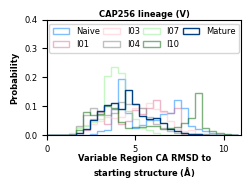

In [5]:
plt.figure(figsize=[2.5,1.5])
bins=np.arange(0,11,0.4)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I01_rmsd_values,    bins=bins, weights=I01_eq_probs,   alpha=0.5, edgecolor='palevioletred', label='I01', histtype='step')
plt.hist(I03_rmsd_values,    bins=bins, weights=I03_eq_probs,   alpha=0.5, edgecolor='pink', label='I03', histtype='step')
plt.hist(I04_rmsd_values,    bins=bins, weights=I04_eq_probs,   alpha=0.5, edgecolor='gray', label='I04', histtype='step')
plt.hist(I07_rmsd_values,    bins=bins, weights=I07_eq_probs,   alpha=0.5, edgecolor='lightgreen', label='I07', histtype='step')
plt.hist(I10_rmsd_values,    bins=bins, weights=I10_eq_probs,   alpha=0.5, edgecolor='darkgreen', label='I10', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CAP256 lineage (V)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
#plt.legend(fontsize=6, loc='center left', bbox_to_anchor=(1, 0.5))
plt.legend(fontsize=6, loc='upper center', ncols=4, columnspacing=0.4) 
plt.xlim(0,11)
plt.ylim(0,0.4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}_V_only-styleB.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH103

In [21]:
lineage='CH103'

sys_name = 'CH103_naive_V'
VH_resis = ["1","121"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_mature_V'
VH_resis = ["1","121"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_I32_V'
VH_resis = ["1","121"]
VL_resis = ["2","108"]
I32_rmsd_values, I32_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_I2_V'
VH_resis = ["1","121"]
VL_resis = ["1","108"]
I2_rmsd_values, I2_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I32_rmsd_values,I2_rmsd_values])))


229 [ 4 21 37] [3382 3398 3417]
226 [ 4 21 37] [3325 3341 3360]
228 [ 4 21 37] [3357 3373 3392]
229 [ 4 21 37] [3378 3394 3413]
6.989918947219849


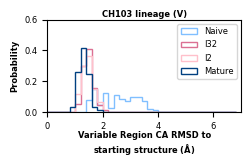

In [24]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,7,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I32_rmsd_values,  bins=bins,weights=I32_eq_probs,        edgecolor='palevioletred', label='I32', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='I2', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH103 lineage (V)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,7)
plt.ylim(0,0.6)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}_V.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH65

In [30]:
lineage = 'CH65'

sys_name = 'CH65_naive_V'
VH_resis = ["1","126"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH65_mature_V'
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH65_I2_V'
I2_rmsd_values, I2_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I2_rmsd_values])))

234 [ 4 21 37] [3438 3452 3468]
234 [ 4 19 35] [3430 3444 3460]
234 [ 4 21 37] [3448 3462 3478]
3.3904042840003967


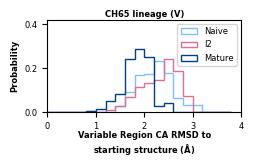

In [32]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='palevioletred',          label='I2', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH65 lineage (V)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,4)
plt.ylim(0,0.42)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}_V.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()